In [ ]:
#this cell defines our bipartite graph, and determines their degrees/ranks using subgraph centrality, sc which was calculated using networkx (nx.subgraph_centrality).
# we used it later to validate our exact SC(calculated using numpy)

import networkx as nx

# Define the graph
G = nx.Graph([
    ('u0', 'v0'),
    ('u0', 'v1'),
    ('u0', 'v2'),
    ('u0', 'v3'),

    ('u1', 'v0'),
    ('u1', 'v1'),
    ('u1', 'v3'),

    ('u2', 'v1'),
    ('u2', 'v2'),

    ('u3', 'v0'),
])

# Subgraph centrality
sc = nx.subgraph_centrality(G)

print("Subgraph centrality:")
for node in sorted(sc):
    print(f"{node}: {sc[node]:.6f}")

# Normalized subgraph centrality
#only added to guard against overflow for large lamda. Not used anywhere else in the pipeline

sc_norm = nx.subgraph_centrality(G, normalized=True)

print("\nNormalized subgraph centrality:")
for node in sorted(sc_norm):
    print(f"{node}: {sc_norm[node]:.6f}")

# Degree of each node
print("\nDegrees:")
for node in sorted(G.nodes()):
    print(f"{node}: {G.degree(node)}")

Subgraph centrality:
u0: 4.617179
u1: 3.572658
u2: 2.468728
u3: 1.653540
v0: 3.458822
v1: 3.628745
v2: 2.526476
v3: 2.698061

Normalized subgraph centrality:
u0: 0.289212
u1: 0.223785
u2: 0.154637
u3: 0.103575
v0: 0.216654
v1: 0.227298
v2: 0.158254
v3: 0.169002

Degrees:
u0: 4
u1: 3
u2: 2
u3: 1
v0: 3
v1: 3
v2: 2
v3: 2


In [ ]:
#this cell is for calculating SC using numpy. we use these SC values throughtout the project
import networkx as nx
import numpy as np
from scipy.linalg import expm

G = nx.Graph([
    ('u0','v0'),('u0','v1'),('u0','v2'),('u0','v3'),
    ('u1','v0'),('u1','v1'),('u1','v3'),
    ('u2','v1'),('u2','v2'),
    ('u3','v0'),
])

nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

beta = 1.0
E = expm(beta * A)
SC_exact = dict(zip(nodes, np.diag(E)))

for n in nodes:
    print(f"{n}: {SC_exact[n]:.6f}")

sc_nx = nx.subgraph_centrality(G)
print("max |difference| vs networkx:", max(abs(sc_nx[n]-SC_exact[n]) for n in nodes))

u0: 4.617179
u1: 3.572658
u2: 2.468728
u3: 1.653540
v0: 3.458822
v1: 3.628745
v2: 2.526476
v3: 2.698061
max |difference| vs networkx: 1.3322676295501878e-13


In [ ]:
#this cell normalizes the adjacency matrix and builds the even Chebyshev polynomial of cosh(zx)/cosh(z).
#DELTA is the fixed target for the SC error. The polynomial degree is the smallest one whose truncation error, multiplied by cosh(z), stays below DELTA.
#the same DELTA is used in every later cell of this notebook, and it is chosen without looking at any classical score.
import numpy as np
from scipy.special import ive
from numpy.polynomial import chebyshev as C

DELTA = 1e-4   # target absolute error on the SC scale; SC(v) >= 1 for unweighted graphs, so it also bounds the relative error

# ---------- normalize the adjacency matrix ----------
beta = 1.0
lam = np.max(np.abs(np.linalg.eigvalsh(A)))                    # spectral norm of A
alpha = 1.001 * max(lam, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # also covers PennyLane's BlockEncode rule
z = beta * alpha
print(f"spectral norm = {lam:.6f}   alpha = {alpha:.6f}   z = beta*alpha = {z:.6f}")
print(f"cosh(z) = {np.cosh(z):.4f}\n")

# ---------- Chebyshev (Bessel) coefficients of cosh(zx)/cosh(z), even branch only ----------
def cheb_coeffs(z, deg):
    """weights of T_0, T_1, ..., T_deg; odd entries are zero because cosh is even"""
    k = np.arange(deg + 1) #creates polynomial degrees
    c = 2.0 * ive(k, z) # taking bessel, but it scales the factor by e^-z
    c[0] = ive(0, z) # T0 doesnt have the factor 2
    c[k % 2 == 1] = 0.0  #not taking the odd degrees
    return c / (0.5 * (1 + np.exp(-2 * z))) # divide by cosh(z) and scaled by e^z to match ive

def tail_error(z, deg):
    """exact worst-case error = sum of the discarded weights"""
    c_full = cheb_coeffs(z, deg + 60) #using the func we built taking 60 more terms.(roughly taken 60, havent compared with higher degree)
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, max_deg=200): # determining upto how many degrees to keep
    d = 0                                          # even branch: only even degrees
    while tail_error(z, d) > eps:
        d += 2
        if d > max_deg:
            raise RuntimeError("tolerance not reached; raise max_deg")
    return d, cheb_coeffs(z, d)

d_e, c_e = degree_for_eps(z, DELTA / np.cosh(z))
print(f"even branch degree: {d_e}   tail error: {tail_error(z, d_e):.3e}")
print(f"weights on T0, T2, T4, ...: {np.round(c_e[::2], 6)}\n")

# ---------- verify admissibility ----------
def check_admissibility(c, z):
    xs = np.linspace(-1, 1, 200_001)               # the grid of test points
    P = C.chebval(xs, c)                           # the polynomial at every grid point
    target = np.cosh(z * xs) / np.cosh(z)          # the exact function at every grid point using NumPy's hyperbolic cosine function

    grid_error = np.max(np.abs(P - target))
    parity_violation = np.max(np.abs(C.chebval(-xs, c) - P))     # even: P(-x) must equal P(x)
    max_abs_P = np.max(np.abs(P))
    admissible = max_abs_P <= 1.0

    print("even (cosh) branch:")
    print(f"  1. grid evaluation : worst-case error vs target = {grid_error:.3e}")
    print(f"  2. parity check    : max deviation = {parity_violation:.2e}  "
          f"-> {'OK' if parity_violation < 1e-9 else 'FAILED'}")
    print(f"  3. admissibility   : max|P(x)| = {max_abs_P:.10f}  "
          f"-> {'OK, no scaling needed' if admissible else 'OVERSHOOT -- needs delta scaling'}")

    c_safe, delta = c, 0.0
    if not admissible:
        delta = (1.0 - 1.0 / max_abs_P) * 1.01
        c_safe = c * (1 - delta)
        print(f"     applying delta = {delta:.2e}; divide recovered amplitude by {1-delta:.6f} later")
    return c_safe, delta

c_e_safe, delta_e = check_admissibility(c_e, z)
print(f"\nSC error bound on the SC scale: cosh(z) * tail error = {np.cosh(z) * tail_error(z, d_e):.2e}")

spectral norm = 2.770380   alpha = 3.165440   z = beta*alpha = 3.165440
cosh(z) = 11.8707

even branch degree: 8   tail error: 5.845e-06
weights on T0, T2, T4, ...: [4.70581e-01 4.52653e-01 7.13230e-02 5.22100e-03 2.17000e-04]

even (cosh) branch:
  1. grid evaluation : worst-case error vs target = 5.845e-06
  2. parity check    : max deviation = 0.00e+00  -> OK
  3. admissibility   : max|P(x)| = 0.9999941546  -> OK, no scaling needed

SC error bound on the SC scale: cosh(z) * tail error = 6.94e-05


In [ ]:
!pip install pyqsp -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 63.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 31.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 93.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 61.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 87.0 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [ ]:
# this cell is blockencoding the adjacency matrix using pennylane's function
import numpy as np, pennylane as qml
from scipy.linalg import expm

beta = 1.0
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))  # 3.165440
z = beta * alpha
At = A / alpha
print("alpha =", alpha, " norm(At) =", np.linalg.norm(At, 2)) #checking to make sure the norm is less than 1

BE = qml.BlockEncode(At, wires=range(4)) # the unitary matrix is a 2^4x2^4 (4 qubits, hilbert space dim=16)
U = qml.matrix(BE)
print("U shape:", U.shape)
print("unitary error:", np.abs(U @ U.conj().T - np.eye(16)).max())
print("top-left block equals At:", np.allclose(U[:8, :8], At))

alpha = 3.1654399378285474  norm(At) = 0.8751959628328735
U shape: (16, 16)
unitary error: 1.5543122344752192e-15
top-left block equals At: True


In [ ]:
#this cell finds the angles for the polynomial of degree d_e (set by DELTA in the polynomial cell) and checks that the QSVT circuit applies that polynomial to Ã,
#then averages the circuit with its mirror to get the real part and compares the resulting SC estimates with the exact ones.
from scipy.special import ive
from numpy.polynomial import chebyshev as C

def cheb_coeffs(z, deg, parity=0):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z)
    c[(k % 2) != parity] = 0.0
    return c / (0.5 * (1 + np.exp(-2 * z)))

deg = d_e                                   # degree set by DELTA in the polynomial cell
c = cheb_coeffs(z, deg)
poly = C.cheb2poly(c)                       # monomial form needed for PennyLane
angles = qml.poly_to_angles(poly, "QSVT")   # classical phase finding means this function solves the angles for us. The function qml.poly_to_angles() takes the polynomial coefficients and calculates a sequence of angles for qsvt
print("degree:", deg, "  number of angles:", len(angles))     # one more angle than the degree

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=8, wires=range(4)) for a in ang]  ## one phase gate(a 16x16 matrix) per angle, vertex states get e^(+ia), the other 8 get e^(-ia)
    M = qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))      #QSVT(BE, projs) builds the circuit by alternating the Ã box (BE) with the phase gates
    return M[:8, :8]                                              #we keep only the top-left 8×8 corner

blk = qsvt_block(angles)  #This runs the qsvt circuit
w, V = np.linalg.eigh(At)  #
P_At = (V * C.chebval(w, c)) @ V.T          # classically calculating exact P(Ã)
print("max |imag(block)|        :", np.abs(blk.imag).max())  #We print it only to show that the raw circuit output is complex, and so to explain why the real-part trick is needed afterwards.
print("max |real(block) - P(Ã)| :", np.abs(blk.real - P_At).max())

# real part: average the circuit with its mirror (negated angles)
blk_re = (blk + qsvt_block(-np.array(angles))) / 2
sc_est = np.cosh(z) * np.diag(blk_re).real #the circuit’s sc estimate
sc_exact = np.diag(expm(beta * A))
print("SC exact  :", np.round(sc_exact, 6))
print("SC circuit:", np.round(sc_est, 6))
print("max abs error:", np.abs(sc_est - sc_exact).max())

degree: 8   number of angles: 9
max |imag(block)|        : 0.4718533564004798
max |real(block) - P(Ã)| : 3.8902214782865485e-13
SC exact  : [4.617179 3.572658 2.468728 1.65354  3.458822 3.628745 2.526476 2.698061]
SC circuit: [4.617175 3.572637 2.468709 1.653507 3.45879  3.628738 2.526454 2.698046]
max abs error: 3.225014751118138e-05


max |response - P|      : 1.000310945187266e-12
max |response - target| : 5.8453984328465936e-06


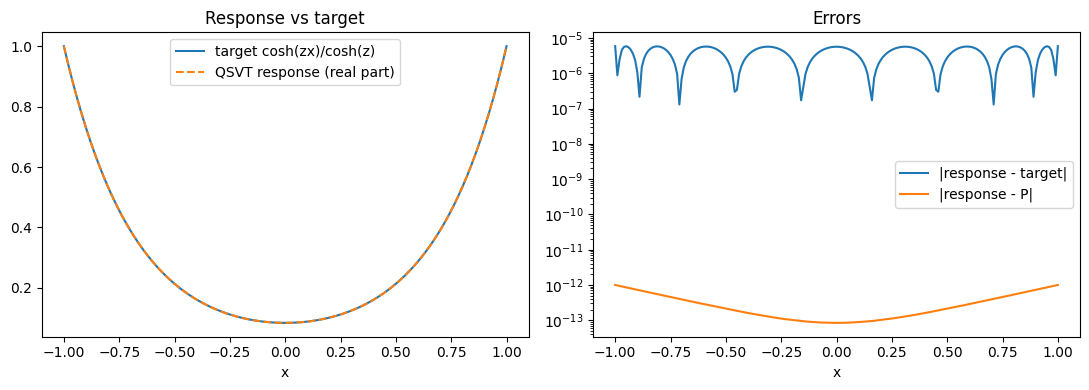

In [ ]:
import matplotlib.pyplot as plt
#For this response plot only, we replace the matrix Ã with a single number x and sweep x across [−1, 1]
def response_at(x, ang):
    be = qml.BlockEncode(np.array([[x]]), wires=[0])
    projs = [qml.PCPhase(a, dim=1, wires=[0]) for a in ang]
    return qml.matrix(qml.QSVT(be, projs), wire_order=[0])[0, 0]

xs = np.linspace(-1, 1, 201)
r1 = np.array([response_at(x, angles) for x in xs])
r2 = np.array([response_at(x, -np.array(angles)) for x in xs])
resp = ((r1 + r2) / 2).real                 # real-part average, as before

P = C.chebval(xs, c)                        # the polynomial of degree d_e
target = np.cosh(z * xs) / np.cosh(z)       # exact function

print("max |response - P|      :", np.abs(resp - P).max())  #checking if The circuit matches our polynomial almost exactly.i.e if the angles are correct.
print("max |response - target| :", np.abs(resp - target).max()) #The truncation error

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(xs, target, label="target cosh(zx)/cosh(z)")
ax[0].plot(xs, resp, "--", label="QSVT response (real part)")
ax[0].legend(); ax[0].set_xlabel("x"); ax[0].set_title("Response vs target")
ax[1].semilogy(xs, np.abs(resp - target) + 1e-16, label="|response - target|")
ax[1].semilogy(xs, np.abs(resp - P) + 1e-16, label="|response - P|")
ax[1].legend(); ax[1].set_xlabel("x"); ax[1].set_title("Errors")
plt.tight_layout(); plt.show()

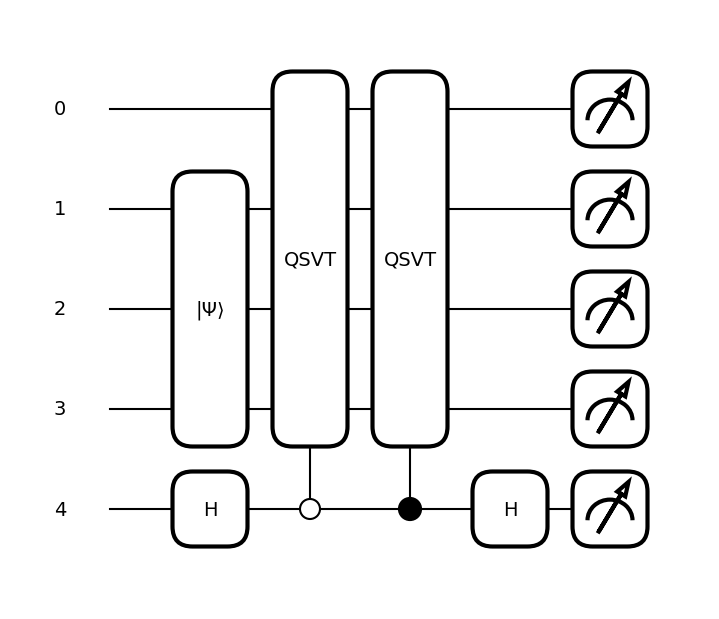

p_success per vertex : [0.1513 0.0906 0.0433 0.0194 0.0849 0.0934 0.0453 0.0517]
cosh(z)*sqrt(p)      : [4.617175 3.572637 2.468709 1.653507 3.45879  3.628738 2.526454 2.698046]
SC exact             : [4.617179 3.572658 2.468728 1.65354  3.458822 3.628745 2.526476 2.698061]
true ranking: ['u0', 'v1', 'u1', 'v0', 'v3', 'v2', 'u2', 'u3']
shots/vertex | full ranking ok | v1>u1 ok | mean abs SC err
         100 |           0.004 |    0.450 |          0.4812
        1000 |           0.100 |    0.569 |          0.1441
       10000 |           0.523 |    0.768 |          0.0454
      100000 |           0.975 |    0.988 |          0.0144
     1000000 |           1.000 |    1.000 |          0.0045


In [ ]:
#this cel builds the 5-qubit real-part circuit (drawn as circuit_5q.png) and reads the success probability for each vertex, which gives its SC value.
#Then it simulates finite shots to find how many are needed to get the vertex ranking right.
import matplotlib.pyplot as plt
N = 8
sc_exact = np.diag(expm(beta * A))

dev5 = qml.device("default.qubit", wires=5)   # This creates a simulated quantum computer with 5 qubits. wires 0-3: block encoding, wire 4: real-part ancilla
projs_pos = [qml.PCPhase(a,  dim=N, wires=range(4)) for a in angles] #the phase gates with the angles
projs_neg = [qml.PCPhase(-a, dim=N, wires=range(4)) for a in angles] #the phase gates with the negated angles

@qml.qnode(dev5)   #makes the function a circuit
def real_part_circuit(v):
    bits = [int(b) for b in format(v, "03b")] #turns the vertex number into 3 bits
    qml.BasisState(np.array(bits), wires=[1, 2, 3])        # input vertex |v> (the |Ψ⟩ box: sets wires 1–3 to the vertex label)
    qml.Hadamard(wires=4)                #the first H on wire 4
    qml.ctrl(qml.QSVT(BE, projs_pos), control=4, control_values=[0]) #the first QSVT box, with the open circle on wire 4: runs only if wire 4 is 0, with the angles
    qml.ctrl(qml.QSVT(BE, projs_neg), control=4, control_values=[1]) #he second QSVT box, with the filled circle on wire 4: runs only if wire 4 is 1, with the negated angles
    qml.Hadamard(wires=4)                                            #the last H on wire 4: merges the two branches, so the imaginary parts cancel
    return qml.probs(wires=range(5))  #the meters: gives the probability of each of the 32 outcomes of the 5 qubits( where only one of the outcome corresponds to the closed walk)
fig, ax = qml.draw_mpl(real_part_circuit, style="black_white")(5)   # 5 = the vertex number
fig.savefig("circuit_5q.png", dpi=200, bbox_inches="tight")
plt.show()
def p_success(v):         #For each vertex we run the circuit separately, starting at that vertex, and read that one probability where it's a closeed walk
    probs = real_part_circuit(v)
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]   # wire0=0, system=v, wire4=0
    return probs[int("".join(map(str, bits)), 2)]

p = np.array([p_success(v) for v in range(N)])
print("p_success per vertex :", np.round(p, 4))
print("cosh(z)*sqrt(p)      :", np.round(np.cosh(z) * np.sqrt(p), 6)) #get SC, take the square root of p and multiply by cosh(z)
print("SC exact             :", np.round(sc_exact, 6))

# ---- shot sweep: repeat the circuit n times = binomial sampling with probability p ----
rng = np.random.default_rng(1)
names = ["u0", "u1", "u2", "u3", "v0", "v1", "v2", "v3"]
true_order = np.argsort(-sc_exact)
print("true ranking:", [names[i] for i in true_order])
trials = 2000
print(f"{'shots/vertex':>12} | {'full ranking ok':>15} | {'v1>u1 ok':>8} | {'mean abs SC err':>15}")
for n in [100, 1000, 10_000, 100_000, 1_000_000]:
    counts = rng.binomial(n, p, size=(trials, N))
    est = np.cosh(z) * np.sqrt(counts / n)
    rank_ok = np.mean([np.array_equal(np.argsort(-e), true_order) for e in est])
    pair_ok = np.mean(est[:, 5] > est[:, 1])
    err = np.mean(np.abs(est - sc_exact))
    print(f"{n:>12} | {rank_ok:>15.3f} | {pair_ok:>8.3f} | {err:>15.4f}")

Counter({'RZ': 1616, 'CNOT': 976, 'RY': 728, 'PhaseShift': 152, 'Hadamard': 82, 'RX': 20, 'PauliX': 18})
total gates: 3592  CNOTs: 976
ideal-compiled max SC err: 3.2250147487644654e-05
err/CNOT-qubit | rank ok | max SC err | u1-v1 gap kept
         0e+00 |    True |      0.000 |          1.000
         1e-04 |    True |      0.332 |          0.850
         3e-04 |    True |      0.903 |          0.612
         1e-03 |    True |      2.160 |          0.185
         3e-03 |   False |      2.904 |         -0.003
         1e-02 |   False |      2.684 |         -0.000


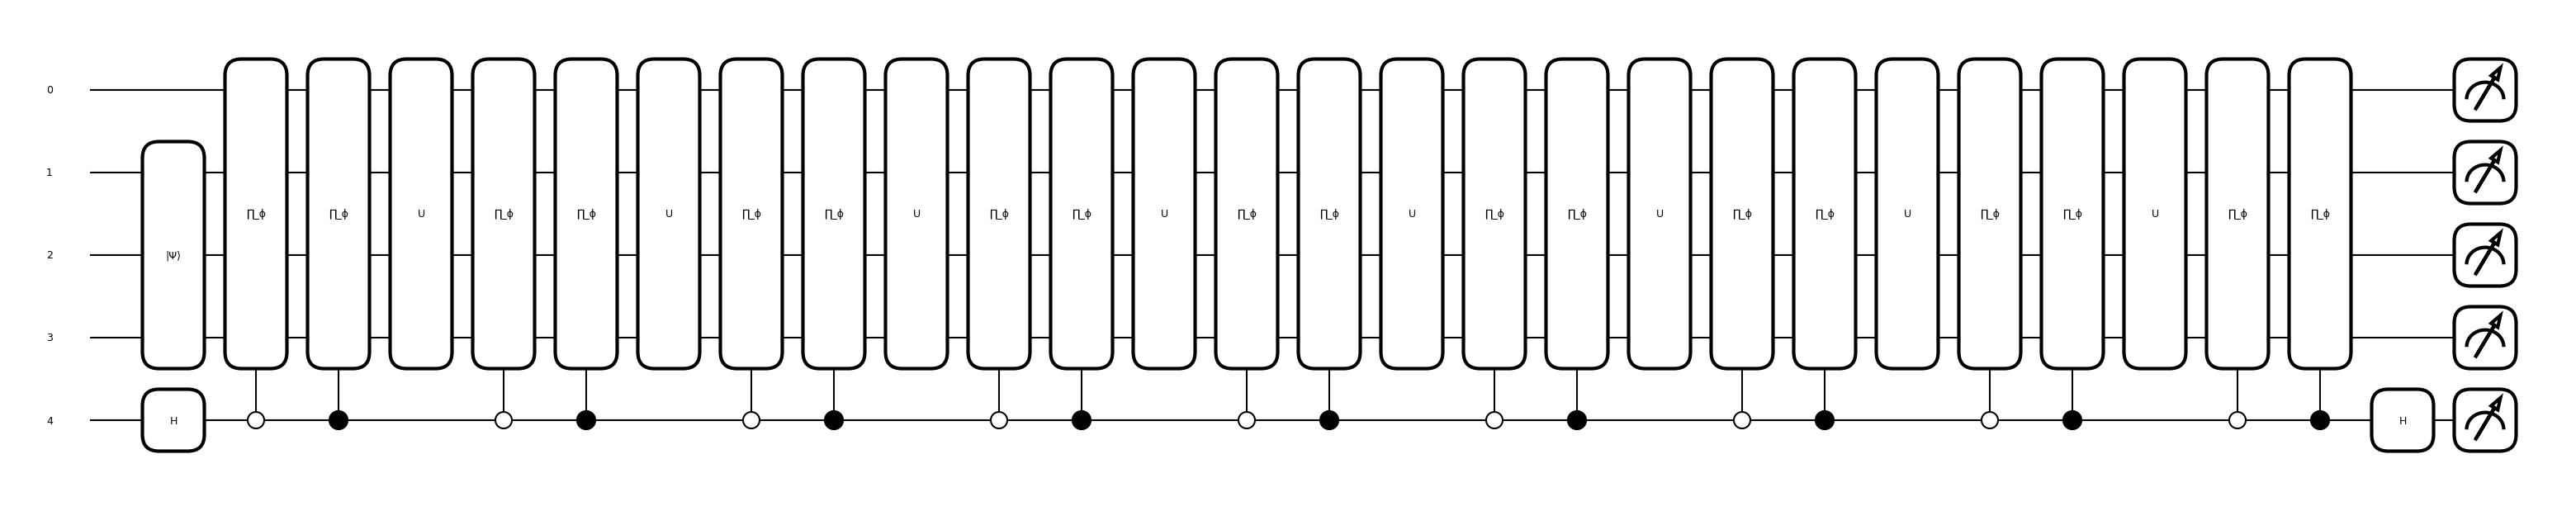

In [ ]:
#This cell asks how much gate noise the circuit can tolerate. It rebuilds the 5-qubit circuit gate by gate and compiles it into basic gates (the gate and CNOT counts are printed below).
#Then it adds depolarizing noise after every CNOT, sweeps the error rate from 0 to 10⁻², and reports when the SC values go wrong and when the vertex ranking breaks.
from collections import Counter
N = 8
sc_exact = np.diag(expm(beta * A))
true_order = np.argsort(-sc_exact)

def flatten(ops):          #flattening qsvt into phases and boxes
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
base_ops = flatten(qml.QSVT(BE, projs).decomposition())

def real_part_ops(v):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):      # asks whether this piece is a phase gate, only the phase rotations are controlled
            a = op.data[0]                     #reads its angle a
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0]) #it adds two controlled gates: the phase with a if wire 4 is 0, and the phase with −a if wire 4 is 1
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:                                # block encoding (or its adjoint) as an explicit unitary
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4)) #If the piece is a box call,There is no control on wire 4 here, because both branches use the same box
    qml.Hadamard(wires=4)
@qml.qnode(qml.device("default.qubit", wires=5))
def flat_circuit(v):
    real_part_ops(v)
    return qml.probs(wires=range(5))   #It picks the success probability out of the 32 outcomes just like p_success

fig, ax = qml.draw_mpl(flat_circuit, style="black_white", fontsize=9)(5)
fig.savefig("circuit_flat.png", dpi=160, bbox_inches="tight")
def p_target(probs, v):
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]
    return probs[int("".join(map(str, bits)), 2)]

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard,
            qml.PauliX, qml.PhaseShift, qml.GlobalPhase}

# ---- ideal compiled circuit + gate count ----
#This part compiles the circuit into basic gates, counts them, and checks that the answer didn’t change.
dev = qml.device("default.qubit", wires=5)
@qml.transforms.decompose(gate_set=gate_set)
@qml.qnode(dev)
def compiled(v):
    real_part_ops(v)
    return qml.probs(wires=range(5))

tape = qml.workflow.construct_tape(compiled)(0)
ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
print(Counter(o.name for o in ops))
print("total gates:", len(ops), " CNOTs:", sum(isinstance(o, qml.CNOT) for o in ops))
p_ideal = np.array([p_target(compiled(v), v) for v in range(N)])
print("ideal-compiled max SC err:", np.abs(np.cosh(z) * np.sqrt(p_ideal) - sc_exact).max())

# ---- depolarizing noise on every CNOT ----#This defines a function that runs the compiled circuit with noise after every CNOT
dev_m = qml.device("default.mixed", wires=5)
def run_noisy(p2):
    def cnot_noise(op, **kw):
        qml.DepolarizingChannel(p2, wires=op.wires[0])
        qml.DepolarizingChannel(p2, wires=op.wires[1])
    nm = qml.NoiseModel({qml.noise.op_eq(qml.CNOT): cnot_noise})
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_m)
    def circ(v):
        real_part_ops(v)
        return qml.probs(wires=range(5))
    return np.array([p_target(circ(v), v) for v in range(N)])

print(f"{'err/CNOT-qubit':>14} | {'rank ok':>7} | {'max SC err':>10} | {'u1-v1 gap kept':>14}")
for p2 in [0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]:
    pn = run_noisy(p2)
    est = np.cosh(z) * np.sqrt(pn)
    rank_ok = np.array_equal(np.argsort(-est), true_order)
    gap = (pn[5] - pn[1]) / (p_ideal[5] - p_ideal[1])     # vertex 5 = v1, vertex 1 = u1
    print(f"{p2:>14.0e} | {str(rank_ok):>7} | {np.abs(est - sc_exact).max():>10.3f} | {gap:>14.3f}")

In [ ]:
#This cell repeats the whole calculation for five values of β (0.5, 1, 1.5, 2, 3) to find which β is the best operating point. For each β it:
#picks the smallest even polynomial degree that keeps the SC error below a fixed target DELTA, chosen before any classical score is computed,
#finds the angles and runs the ideal QSVT circuit (at the matrix level, with no gate noise),
#only then computes the classical scores, to check the circuit's SC error and ranking, and prints how many shots are needed for a 95% correct ranking.
import pandas as pd
from scipy.special import ive
from numpy.polynomial import chebyshev as C

N = 8
names = ["u0","u1","u2","u3","v0","v1","v2","v3"]
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))   # fixed, depends only on A
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
w_, V_ = np.linalg.eigh(At)

def cheb_coeffs(z, deg):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z)
    c[(k % 2) != 0] = 0.0
    return c / (0.5 * (1 + np.exp(-2 * z)))

def tail_error(z, deg):
    c_full = cheb_coeffs(z, deg + 60)
    return float(np.sum(np.abs(c_full[deg + 1:])))

def degree_for_eps(z, eps, max_deg=300):
    d = 0
    while tail_error(z, d) > eps:
        d += 2
        if d > max_deg: raise RuntimeError("raise max_deg")
    return d

def qsvt_block(ang):
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in ang]
    return qml.matrix(qml.QSVT(BE, projs), wire_order=range(4))[:N, :N]

def min_rel_gap(sc):
    v = np.sort(sc)
    return np.min(np.diff(v) / v[1:])

rng = np.random.default_rng(7)
def shots_for_ranking(p, true_order, target=0.95, trials=400):
    for n in np.unique(np.logspace(2, 10, 33).astype(np.int64)):
        counts = rng.binomial(n, p, size=(trials, N))
        ok = np.mean([np.array_equal(np.argsort(-c), true_order) for c in counts])
        if ok >= target: return int(n)
    return None

rows, rankings = [], {}
for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    z = beta * alpha
    eps = DELTA / np.cosh(z)                      # SC error <= DELTA, fixed before any classical score is computed
    d = degree_for_eps(z, eps)
    c = cheb_coeffs(z, d)
    angles = qml.poly_to_angles(C.cheb2poly(c), "QSVT")
    blk = qsvt_block(angles)
    blk_re = (blk + qsvt_block(-np.array(angles))) / 2
    P_At = (V_ * C.chebval(w_, c)) @ V_.T
    chk = np.abs(blk_re - P_At).max()
    p = np.diag(blk_re).real ** 2
    sc_circ = np.cosh(z) * np.sqrt(p)
    # classical reference, used only to check the circuit
    sc = np.diag(expm(beta * A))
    true_order = np.argsort(-sc)
    abs_gap = np.min(np.diff(np.sort(sc)))
    n_need = shots_for_ranking(p, true_order)
    rows.append({
        "beta": beta,
        "z": f"{z:.2f}",
        "SC max/min": f"{sc.max()/sc.min():.2f}",
        "gap (rel)": f"{min_rel_gap(sc)*100:.2f}%",
        "gap (abs)": f"{abs_gap:.4f}",
        "degree": d,
        "poly error": f"{tail_error(z, d):.1e}",
        "circuit SC error": f"{np.abs(sc_circ - sc).max():.1e}",
        "rank ok": bool(np.array_equal(np.argsort(-sc_circ), true_order)),
        "p min": f"{p.min():.4f}",
        "p max": f"{p.max():.4f}",
        "shots (95% rank)": f"{n_need:,}" if n_need else "none",
        "circuit vs poly": f"{chk:.0e}",
    })
    rankings[beta] = " > ".join(names[i] for i in true_order)

print(f"alpha = {alpha:.6f}\n")
print(pd.DataFrame(rows).to_string(index=False))
print()
if len(set(rankings.values())) == 1:
    print("True ranking (same for every beta):", next(iter(rankings.values())))
else:
    for b, r in rankings.items(): print(f"True ranking at beta = {b}: {r}")

alpha = 3.165440

 beta    z SC max/min gap (rel) gap (abs)  degree poly error circuit SC error  rank ok  p min  p max shots (95% rank) circuit vs poly
  0.5 1.58       1.40     0.20%    0.0028       6    3.2e-06          5.0e-06     True 0.1996 0.3895        1,778,279           6e-13
  1.0 3.17       2.79     1.55%    0.0561       8    5.8e-06          3.2e-05     True 0.0194 0.1513          100,000           4e-13
  1.5 4.75       5.35     3.33%    0.4084      12    1.1e-07          3.2e-06     True 0.0030 0.0852           56,234           3e-13
  2.0 6.33       8.41     4.58%    2.1150      14    6.4e-08          8.4e-06     True 0.0008 0.0545           31,622           2e-13
  3.0 9.50      12.31     5.59%   40.0540      18    1.3e-08          6.1e-05     True 0.0002 0.0242           56,234           2e-13

True ranking (same for every beta): u0 > v1 > u1 > v0 > v3 > v2 > u2 > u3


In [ ]:
#This cell runs the CNOT-noise sweep for several β (1.5 and 2.0 by default). For each β it builds the circuit at the degree set by the fixed target DELTA (defined in the polynomial cell), and adds depolarizing noise after every CNOT.
#The classical scores are computed only after the circuit is built, to check it. It then reports at which noise level the SC values and the ranking break, and how much of the closest pair's gap survives.
import time
N = 8
names = ["u0","u1","u2","u3","v0","v1","v2","v3"]
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard, qml.PauliX, qml.PhaseShift, qml.GlobalPhase}
dev_ideal = qml.device("default.qubit", wires=5)
dev_mixed = qml.device("default.mixed", wires=5)

def cheb_coeffs(z, deg):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z); c[(k % 2) != 0] = 0.0
    return c / (0.5 * (1 + np.exp(-2 * z)))
def tail_error(z, deg):
    return float(np.sum(np.abs(cheb_coeffs(z, deg + 60)[deg + 1:])))
def degree_for_eps(z, eps):
    d = 0
    while tail_error(z, d) > eps: d += 2
    return d
def flatten(ops):
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out
def p_target(probs, v):
    bits = [0] + [int(b) for b in format(v, "03b")] + [0]
    return probs[int("".join(map(str, bits)), 2)]

def noise_sweep_for_beta(beta, noise_levels):
    z = beta * alpha
    deg = degree_for_eps(z, DELTA / np.cosh(z))              # fixed target, set before any classical score is computed
    angles = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg)), "QSVT")
    projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
    base_ops = flatten(qml.QSVT(BE, projs).decomposition())

    def real_part_ops(v):
        bits = [int(b) for b in format(v, "03b")]
        qml.BasisState(np.array(bits), wires=[1, 2, 3])
        qml.Hadamard(wires=4)
        for op in base_ops:
            if isinstance(op, qml.PCPhase):
                a = op.data[0]
                qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])
                qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
            else:
                qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))
        qml.Hadamard(wires=4)

    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_ideal)
    def compiled(v):
        real_part_ops(v); return qml.probs(wires=range(5))
    tape = qml.workflow.construct_tape(compiled)(0)
    ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
    n_cnot = sum(isinstance(o, qml.CNOT) for o in ops)
    p_ideal = np.array([p_target(compiled(v), v) for v in range(N)])

    sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)     # classical reference, used only to check the circuit
    order = np.argsort(-sc_exact)
    rel = [(sc_exact[order[k]] - sc_exact[order[k+1]]) / sc_exact[order[k]] for k in range(N-1)]
    k = int(np.argmin(rel)); hi, lo = order[k], order[k+1]
    print(f"\nbeta = {beta}  z = {z:.3f}  degree = {deg}  gates = {len(ops)}  CNOTs = {n_cnot}  "
          f"closest pair = {names[hi]}/{names[lo]} ({rel[k]*100:.2f}% apart)")
    print(f"{'error/CNOT-qubit':>16} | {'rank ok':>7} | {'max rel SC err':>14} | {'closest-pair gap kept':>21}")
    for p2 in noise_levels:
        def cnot_noise(op, **kw):
            qml.DepolarizingChannel(p2, wires=op.wires[0])
            qml.DepolarizingChannel(p2, wires=op.wires[1])
        nm = qml.NoiseModel({qml.noise.op_eq(qml.CNOT): cnot_noise})
        @qml.add_noise(nm)
        @qml.transforms.decompose(gate_set=gate_set)
        @qml.qnode(dev_mixed)
        def noisy(v):
            real_part_ops(v); return qml.probs(wires=range(5))
        pn = np.array([p_target(noisy(v), v) for v in range(N)])
        est = np.cosh(z) * np.sqrt(pn)
        rank_ok = np.array_equal(np.argsort(-est), true_order)
        err = np.max(np.abs(est - sc_exact) / sc_exact)
        gap = (pn[hi] - pn[lo]) / (p_ideal[hi] - p_ideal[lo])
        print(f"{p2:>16.0e} | {str(rank_ok):>7} | {err:>14.3f} | {gap:>21.3f}")

betas = [1.5, 2.0]            # β = 0.5 and 3.0 are run in the last cell; β = 1.0 is covered by the full noise study cell
noise_levels = [0.0, 1e-4, 3e-4, 1e-3, 3e-3]
for b in betas:
    t0 = time.time()
    noise_sweep_for_beta(b, noise_levels)
    print(f"({time.time()-t0:.0f}s)")


beta = 1.5  z = 4.748  degree = 12  gates = 5380  CNOTs = 1462  closest pair = v1/u1 (3.33% apart)
error/CNOT-qubit | rank ok | max rel SC err | closest-pair gap kept
           0e+00 |    True |          0.000 |                 1.000
           1e-04 |    True |          0.145 |                 0.803
           3e-04 |    True |          0.378 |                 0.518
           1e-03 |    True |          0.907 |                 0.114
           3e-03 |   False |          1.527 |                 0.002
(163s)

beta = 2.0  z = 6.331  degree = 14  gates = 6274  CNOTs = 1705  closest pair = v1/u1 (4.58% apart)
error/CNOT-qubit | rank ok | max rel SC err | closest-pair gap kept
           0e+00 |    True |          0.000 |                 1.000
           1e-04 |    True |          0.690 |                 0.787
           3e-04 |    True |          1.456 |                 0.491
           1e-03 |    True |          2.731 |                 0.102
           3e-03 |   False |          3.988 |

In [ ]:
#This is the full Step 21 noise study for a single β (set at the top, 1.0 or 1.5). It builds the compiled circuit at the degree set by the fixed target DELTA (defined in the polynomial cell), prints its gate count and depth, then sweeps three kinds of noise separately.
#For each noise level, it prints how far the SC values are off (MAE and the largest per-vertex relative error), how well the ranking holds (Spearman and Kendall correlations), and
#whether the top vertex, the top-3 set, and the full ranking are still correct. At the end it lists, for each noise type, the first level where the values exceed 5% error,
#the ranking changes, the top-3 set fails, and the top vertex fails. The classical scores are computed after the circuit is built and are used only to check it.
beta = 1.0          # or 1.5
QUICK = False       # True = one level per noise type, for a fast test

from scipy.stats import spearmanr, kendalltau
N = 8
names = ["u0","u1","u2","u3","v0","v1","v2","v3"]
lam_max = np.max(np.abs(np.linalg.eigvalsh(A)))
alpha = 1.001 * max(lam_max, np.sqrt(np.max(np.abs(A @ A).sum(axis=1))))
At = A / alpha
BE = qml.BlockEncode(At, wires=range(4))
z = beta * alpha

def cheb_coeffs(z, deg):
    k = np.arange(deg + 1)
    c = 2.0 * ive(k, z); c[0] = ive(0, z); c[(k % 2) != 0] = 0.0
    return c / (0.5 * (1 + np.exp(-2 * z)))
def tail_error(z, deg): return float(np.sum(np.abs(cheb_coeffs(z, deg + 60)[deg + 1:])))
def degree_for_eps(z, eps):
    d = 0
    while tail_error(z, d) > eps: d += 2
    return d
def flatten(ops):
    out = []
    for o in ops:
        if type(o).__name__ == "ChangeOpBasis": out += flatten(list(o.operands))
        else: out.append(o)
    return out

deg = degree_for_eps(z, DELTA / np.cosh(z))      # fixed target, set before any classical score is computed
angles = qml.poly_to_angles(C.cheb2poly(cheb_coeffs(z, deg)), "QSVT")
projs = [qml.PCPhase(a, dim=N, wires=range(4)) for a in angles]
base_ops = flatten(qml.QSVT(BE, projs).decomposition())

def real_part_ops(v):
    bits = [int(b) for b in format(v, "03b")]
    qml.BasisState(np.array(bits), wires=[1, 2, 3])
    qml.Hadamard(wires=4)
    for op in base_ops:
        if isinstance(op, qml.PCPhase):
            a = op.data[0]
            qml.ctrl(qml.PCPhase(a,  dim=N, wires=range(4)), control=4, control_values=[0])
            qml.ctrl(qml.PCPhase(-a, dim=N, wires=range(4)), control=4, control_values=[1])
        else:
            qml.QubitUnitary(qml.matrix(op, wire_order=range(4)), wires=range(4))
    qml.Hadamard(wires=4)

gate_set = {qml.CNOT, qml.RZ, qml.RY, qml.RX, qml.Rot, qml.Hadamard, qml.PauliX, qml.PhaseShift, qml.GlobalPhase}
ONE_Q = [qml.RZ, qml.RY, qml.RX, qml.Hadamard, qml.PauliX, qml.PhaseShift]
dev_ideal = qml.device("default.qubit", wires=5)
dev_mixed = qml.device("default.mixed", wires=5)

@qml.transforms.decompose(gate_set=gate_set)
@qml.qnode(dev_ideal)
def compiled(v):
    real_part_ops(v); return qml.probs(wires=range(5))

tape = qml.workflow.construct_tape(compiled)(0)
ops = [o for o in tape.operations if not isinstance(o, qml.GlobalPhase)]
n_cnot = sum(isinstance(o, qml.CNOT) for o in ops); n_1q = len(ops) - n_cnot
def circuit_depth(op_list):
    level = {}
    for o in op_list:
        d = 1 + max(level.get(w, 0) for w in o.wires)
        for w in o.wires: level[w] = d
    return max(level.values())
depth = circuit_depth(ops)
print(f"beta = {beta}  z = {z:.3f}  degree = {deg}  phases = {len(angles)}  qubits = 5 (3 register + 2 ancilla)")
print(f"compiled: {len(ops)} gates = {n_cnot} CNOT + {n_1q} single-qubit;  depth = {depth}")

def idx(v): return int("".join(map(str, [0] + [int(b) for b in format(v, "03b")] + [0])), 2)

def full_probs(model_dict, v):
    nm = qml.NoiseModel(model_dict)
    @qml.add_noise(nm)
    @qml.transforms.decompose(gate_set=gate_set)
    @qml.qnode(dev_mixed)
    def c(vv): real_part_ops(vv); return qml.probs(wires=range(5))
    return c(v)

def noise_dict(p2=0.0, p1=0.0):
    d = {}
    if p2 > 0:
        def f2(op, **kw):
            qml.DepolarizingChannel(p2, wires=op.wires[0]); qml.DepolarizingChannel(p2, wires=op.wires[1])
        d[qml.noise.op_eq(qml.CNOT)] = f2
    if p1 > 0:
        def f1(op, **kw): qml.DepolarizingChannel(p1, wires=op.wires[0])
        d[qml.noise.op_in(ONE_Q)] = f1
    return d

def readout(probs, r):
    M = np.array([[1 - r, r], [r, 1 - r]])
    out = probs.reshape([2] * 5)
    for ax in range(5): out = np.moveaxis(np.tensordot(M, out, axes=([1], [ax])), 0, ax)
    return out.reshape(-1)

def metrics(pvec):
    est = np.cosh(z) * np.sqrt(np.clip(pvec, 0, None))
    err = np.abs(est - sc_exact)
    return dict(mae=err.mean(), nmae=err.mean() / sc_exact.mean(), maxrel=np.max(err / sc_exact), # Spearman: compares the noisy ranking with the true ranking (1 = same order, 0 = unrelated, -1 = reversed);
                                                                                                       #penalizes vertices that move far from their true position
                rho=spearmanr(est, sc_exact)[0], tau=kendalltau(est, sc_exact)[0],              #Kendall: checks all 28 vertex pairs and counts how many are in the right order vs the wrong order
                                                                                                  #(1 = every pair right; each swapped pair lowers it by 2/28)
                top1=np.argmax(est) == true_order[0],
                top3=set(np.argsort(-est)[:3]) == set(true_order[:3]),
                rank=np.array_equal(np.argsort(-est), true_order))

sc_exact = np.diag(expm(beta * A)); true_order = np.argsort(-sc_exact)     # classical reference, used only to check the circuit
p_ideal = np.array([compiled(v)[idx(v)] for v in range(N)])
base = metrics(p_ideal)
print(f"ideal circuit: MAE = {base['mae']:.4f}  max rel err = {base['maxrel']*100:.2f}%  rank ok = {base['rank']}")

def table(title, label, levels, make_probs):
    print(f"\n{title}")
    print(f"{label:>10} | {'MAE':>7} {'nMAE':>6} {'maxrel':>7} | {'Spearman':>8} {'Kendall':>8} | {'top1':>5} {'top3':>5} {'rank':>5}")
    rows = []
    for lv in levels:
        m = metrics(make_probs(lv)); rows.append((lv, m))
        print(f"{lv:>10.0e} | {m['mae']:>7.3f} {m['nmae']:>6.3f} {m['maxrel']*100:>6.1f}% | {m['rho']:>8.3f} {m['tau']:>8.3f} | "
              f"{str(m['top1']):>5} {str(m['top3']):>5} {str(m['rank']):>5}")
    return rows

if QUICK: L2, L1, LR = [1e-3], [1e-4], [1e-2]
else:
    L2 = [1e-4, 3e-4, 1e-3, 2e-3, 3e-3, 1e-2, 3e-2]
    L1 = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]
    LR = [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]

res2 = table("A. Two-qubit (CNOT) depolarizing noise, per qubit", "p2", L2,
             lambda p: np.array([full_probs(noise_dict(p2=p), v)[idx(v)] for v in range(N)]))
res1 = table("B. Single-qubit depolarizing noise after every 1q gate", "p1", L1,
             lambda p: np.array([full_probs(noise_dict(p1=p), v)[idx(v)] for v in range(N)]))
full_ideal = {v: compiled(v) for v in range(N)}
resr = table("C. Readout error (bit flip on each of 5 measured qubits)", "r", LR,
             lambda r: np.array([readout(full_ideal[v], r)[idx(v)] for v in range(N)]))

def first_fail(rows, key, bad):
    for lv, m in rows:
        if bad(m[key]): return lv
    return None
print("\nThresholds (first tested level where the criterion fails; None = never in the range tested)")
for name, rows in [("CNOT p2", res2), ("1q p1", res1), ("readout r", resr)]:
    print(f"  {name:>10}: values unreliable (max rel err > 5%): {first_fail(rows,'maxrel',lambda x: x>0.05)} | "
          f"ranking changes: {first_fail(rows,'rank',lambda x: not x)} | "
          f"top-3 set fails: {first_fail(rows,'top3',lambda x: not x)} | top-1 fails: {first_fail(rows,'top1',lambda x: not x)}")

beta = 1.0  z = 3.165  degree = 8  phases = 9  qubits = 5 (3 register + 2 ancilla)
compiled: 3592 gates = 976 CNOT + 2616 single-qubit;  depth = 2268
ideal circuit: MAE = 0.0000  max rel err = 0.00%  rank ok = True

A. Two-qubit (CNOT) depolarizing noise, per qubit
        p2 |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3  rank
     1e-04 |   0.209  0.068    7.2% |    1.000    1.000 |  True  True  True
     3e-04 |   0.555  0.180   19.6% |    1.000    1.000 |  True  True  True
     1e-03 |   1.226  0.398   46.8% |    1.000    1.000 |  True  True  True
     2e-03 |   1.448  0.470   60.5% |    1.000    1.000 |  True  True  True
     3e-03 |   1.427  0.464   62.9% |    0.905    0.786 |  True  True False
     1e-02 |   1.215  0.395   58.1% |    0.833    0.643 |  True False False
     3e-02 |   1.100  0.357   54.8% |   -0.929   -0.857 | False False False

B. Single-qubit depolarizing noise after every 1q gate
        p1 |     MAE   nMAE  maxrel | Spearman  Kendall |  top1  top3 

In [ ]:
#This cell runs the same CNOT-noise sweep as the per-β noise cell for the two remaining values, β = 0.5 and β = 3.0, so all five β values of the β sweep are covered.
#it reuses noise_sweep_for_beta from that cell (run that cell first), so the degree again comes from the fixed target DELTA and the classical scores are only used to check the circuit.
import time
noise_levels = [0.0, 1e-4, 3e-4, 1e-3, 3e-3]
for b in [0.5, 3.0]:
    t0 = time.time()
    noise_sweep_for_beta(b, noise_levels)
    print(f"({time.time()-t0:.0f}s)")


beta = 0.5  z = 1.583  degree = 6  gates = 2698  CNOTs = 733  closest pair = v1/u1 (0.20% apart)
error/CNOT-qubit | rank ok | max rel SC err | closest-pair gap kept
           0e+00 |    True |          0.000 |                 1.000
           1e-04 |    True |          0.064 |                 0.667
           3e-04 |    True |          0.177 |                 0.193
           1e-03 |   False |          0.453 |                -0.369
           3e-03 |   False |          0.709 |                -0.162
(81s)

beta = 3.0  z = 9.496  degree = 18  gates = 8062  CNOTs = 2191  closest pair = v1/u1 (5.59% apart)
error/CNOT-qubit | rank ok | max rel SC err | closest-pair gap kept
           0e+00 |    True |          0.000 |                 1.000
           1e-04 |    True |          2.336 |                 0.752
           3e-04 |    True |          4.276 |                 0.443
           1e-03 |    True |          7.228 |                 0.087
           3e-03 |   False |         10.043 |   

In [ ]:
#This cell covers Step 18: it turns simulated shot counts into estimates of the success probabilities and of SC(v), and reports the bias of the square-root estimator, 95% confidence intervals, and vertices left unresolved.
#It uses the ideal success probabilities p_ideal of the compiled β = 1 circuit from the full noise study cell (run that cell first). The exact SC values are not used here: the circuit's own value cosh(z)*sqrt(p) is the target of the statistics.
beta_s = 1.0
z_s = beta_s * alpha
assert np.max(np.abs(np.cosh(z_s) * np.sqrt(p_ideal) - np.diag(expm(beta_s * A)))) < 1e-3, "p_ideal does not belong to beta = 1.0; set beta = 1.0 in the full noise study cell and rerun it"

p_true = p_ideal
sc_circ = np.cosh(z_s) * np.sqrt(p_true)             # value the circuit encodes for each vertex
rng18 = np.random.default_rng(18)
trials = 2000
Z95 = 1.96

def wilson(k, n):
    """95% Wilson interval for a success probability from k successes in n shots; valid also for k = 0"""
    ph = k / n
    centre = (ph + Z95**2 / (2 * n)) / (1 + Z95**2 / n)
    half = Z95 * np.sqrt(ph * (1 - ph) / n + Z95**2 / (4 * n**2)) / (1 + Z95**2 / n)
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)

print(f"weakest vertex: {names[int(np.argmin(p_true))]}  p = {p_true.min():.4f}   (guideline: n_s * p comfortably above 10-20)\n")
print(f"{'shots':>8} | {'min n*p':>8} | {'runs with an unresolved vertex':>30} | {'bias of weakest vertex (measured / predicted)':>46} | {'95% CI coverage':>15}")
for n in [100, 1000, 10_000, 100_000]:
    k = rng18.binomial(n, p_true, size=(trials, N))          # successful events per vertex, per repetition
    p_hat = k / n
    a_hat = np.sqrt(p_hat)                                    # naive amplitude estimate
    unresolved = np.mean((k == 0).any(axis=1))                # a vertex with no successful event is unresolved, not zero
    j = int(np.argmin(p_true))
    bias_meas = a_hat[:, j].mean() / np.sqrt(p_true[j]) - 1
    bias_pred = -1 / (8 * n * p_true[j])
    lo, hi = wilson(k, n)
    covered = (np.cosh(z_s) * np.sqrt(lo) <= sc_circ) & (sc_circ <= np.cosh(z_s) * np.sqrt(hi))
    print(f"{n:>8} | {n * p_true.min():>8.1f} | {unresolved:>29.1%} | {bias_meas:>+22.4f} / {bias_pred:<+21.4f} | {covered.mean():>15.1%}")

# one example experiment at 10^5 shots: estimates with their 95% intervals
n = 100_000
k1 = rng18.binomial(n, p_true)
lo, hi = wilson(k1, n)
print(f"\nOne experiment, {n:,} shots per vertex")
print(f"{'vertex':>6} | {'successes':>9} | {'SC estimate':>11} | {'95% interval':>21} | {'circuit value':>13}")
for v in range(N):
    print(f"{names[v]:>6} | {k1[v]:>9} | {np.cosh(z_s) * np.sqrt(k1[v] / n):>11.4f} | "
          f"[{np.cosh(z_s) * np.sqrt(lo[v]):.4f}, {np.cosh(z_s) * np.sqrt(hi[v]):.4f}] | {sc_circ[v]:>13.4f}")

weakest vertex: u3  p = 0.0194   (guideline: n_s * p comfortably above 10-20)

   shots |  min n*p | runs with an unresolved vertex |  bias of weakest vertex (measured / predicted) | 95% CI coverage
     100 |      1.9 |                         16.8% |                -0.1184 / -0.0644               |           95.3%
    1000 |     19.4 |                          0.0% |                -0.0072 / -0.0064               |           95.0%
   10000 |    194.0 |                          0.0% |                -0.0016 / -0.0006               |           94.9%
  100000 |   1940.3 |                          0.0% |                -0.0000 / -0.0001               |           95.1%

One experiment, 100,000 shots per vertex
vertex | successes | SC estimate |          95% interval | circuit value
    u0 |     15114 |      4.6149 | [4.5811, 4.6489] |        4.6172
    u1 |      8788 |      3.5190 | [3.4840, 3.5543] |        3.5726
    u2 |      4374 |      2.4826 | [2.4469, 2.5189] |        2.4687
    u3